# BITS F464 CIA-2: Predictive Maintenance of Industrial Air Compressors Using Machine Learning

**Student:** Vansh (2024A7PS0149U)
**Course:** BITS F464 Machine Learning
**Instructor:** Prof. Pranav M Pawar

This notebook is a self-contained mini-report. It loads the MetroPT-3 air-compressor dataset, labels failures, explores the data, engineers windowed features, compares nine models, and analyses overfitting, regularization, PCA and feature importance.

In [1]:
!pip install -q numpy pandas matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

sns.set_style("whitegrid")
sns.set_context("notebook")
print("Libraries loaded.")

Libraries loaded.


## 1. Dataset Loading

We use **MetroPT-3**, real sensor data from the air production unit (APU) compressor of a metro train in Porto, Portugal.

- Recorded over about **7 months** (Feb to Aug 2020), roughly **1.5 million records** sampled every 10 seconds
- **7 analog signals:** TP2, TP3, H1, DV_pressure, Reservoirs, Oil_temperature, Motor_current
- **8 digital signals:** COMP, DV_eletric, Towers, MPG, LPS, Pressure_switch, Oil_level, Caudal_impulses
- **4 documented air-leak failures** taken from the operator's maintenance report

In [2]:
import io, os, urllib.request, zipfile

URL = "https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip"
CSV_NAME = "MetroPT3(AirCompressor).csv"

# Primary path: download and unzip the dataset automatically.
# Fallback: if the download fails (site down, no internet), ask for a manual upload.
try:
    if not os.path.exists(CSV_NAME):
        print("Downloading MetroPT-3 from UCI (about 218 MB, may take a minute)...")
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r, open("metropt.zip", "wb") as f:
            while True:
                chunk = r.read(1 << 20)
                if not chunk:
                    break
                f.write(chunk)
        with zipfile.ZipFile("metropt.zip") as z:
            z.extract(CSV_NAME)
    df = pd.read_csv(CSV_NAME)
    print("Loaded", CSV_NAME)
except Exception as e:
    print(f"Automatic download failed ({e}). Falling back to manual upload.")
    from google.colab import files
    print("Please upload MetroPT3(AirCompressor).csv")
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    df = pd.read_csv(io.BytesIO(uploaded[fname]))

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp").sort_index()

print("Shape:", df.shape)
print("\nFirst 3 rows:")
display(df.head(3))
print("\nData types:")
print(df.dtypes)

Please upload MetroPT3(AirCompressor).csv


Saving MetroPT3(AirCompressor).csv to MetroPT3(AirCompressor).csv
Shape: (1516948, 15)

First 3 rows:


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0



Data types:
TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object


In [3]:
print(f"Total rows: {len(df):,}")
print(f"Date range: {df.index.min()}  ->  {df.index.max()}")
print("\nMissing values per column:")
print(df.isna().sum())

Total rows: 1,516,948
Date range: 2020-02-01 00:00:00  ->  2020-09-01 03:59:50

Missing values per column:
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64


## 2. Failure Labeling

The dataset ships without labels. We create them from the operator's maintenance report, which documents four air-leak failures:

| Failure | Start | End |
|---|---|---|
| 1 | 2020-04-18 00:00 | 2020-04-18 23:59 |
| 2 | 2020-05-29 23:30 | 2020-05-30 06:00 |
| 3 | 2020-06-05 10:00 | 2020-06-07 14:30 |
| 4 | 2020-07-15 14:30 | 2020-07-15 19:00 |

Every row inside one of these intervals gets `failure = 1`; all other rows get `failure = 0`.

In [4]:
failures = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
]
failures = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in failures]

df["failure"] = 0
for start, end in failures:
    # End bound inclusive through the last second of the end minute (matches the local pipeline).
    df.loc[start:end + pd.Timedelta("59s"), "failure"] = 1

n_fail = int(df["failure"].sum())
n_norm = len(df) - n_fail
print(f"Normal : {n_norm:,} rows ({100*n_norm/len(df):.2f}%)")
print(f"Failure: {n_fail:,} rows ({100*n_fail/len(df):.2f}%)")

Normal : 1,486,977 rows (98.02%)
Failure: 29,971 rows (1.98%)


## 3. Exploratory Data Analysis

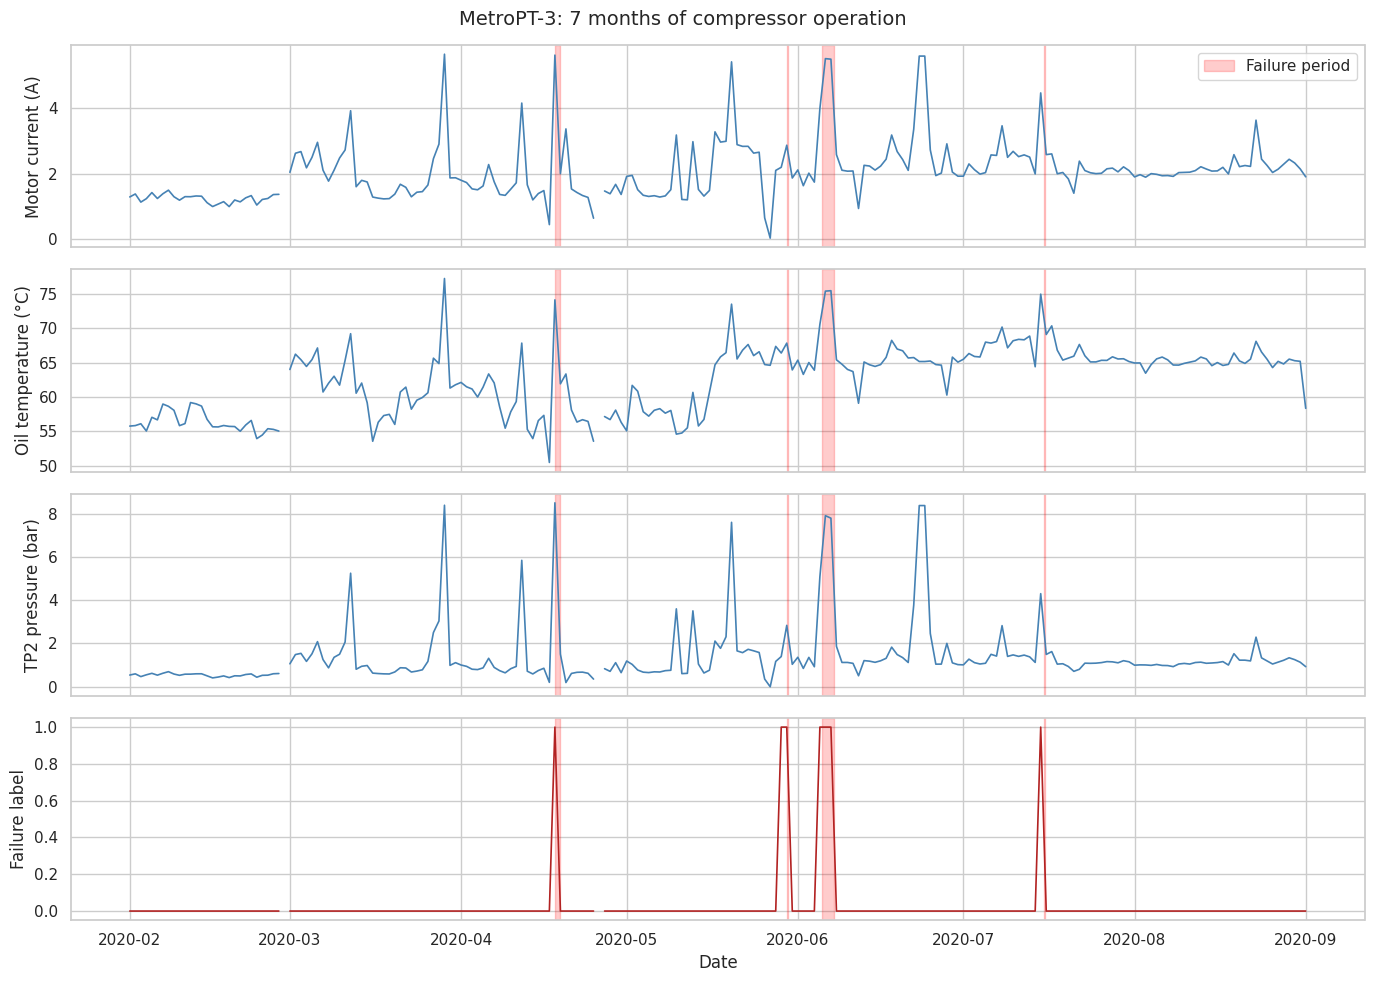

In [5]:
analog = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
digital = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]

daily = df[["Motor_current", "Oil_temperature", "TP2", "failure"]].resample("1D").agg(
    {"Motor_current": "mean", "Oil_temperature": "mean", "TP2": "mean", "failure": "max"})

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
series = [("Motor_current", "Motor current (A)"), ("Oil_temperature", "Oil temperature (°C)"),
          ("TP2", "TP2 pressure (bar)"), ("failure", "Failure label")]
for ax, (col, lab) in zip(axes, series):
    ax.plot(daily.index, daily[col], lw=1.2, color="steelblue" if col != "failure" else "firebrick")
    ax.set_ylabel(lab)
    for i, (s, e) in enumerate(failures):
        ax.axvspan(s, e, color="red", alpha=0.2, label="Failure period" if (i == 0 and col == "Motor_current") else None)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Date")
fig.suptitle("MetroPT-3: 7 months of compressor operation", fontsize=14)
plt.tight_layout()
plt.show()

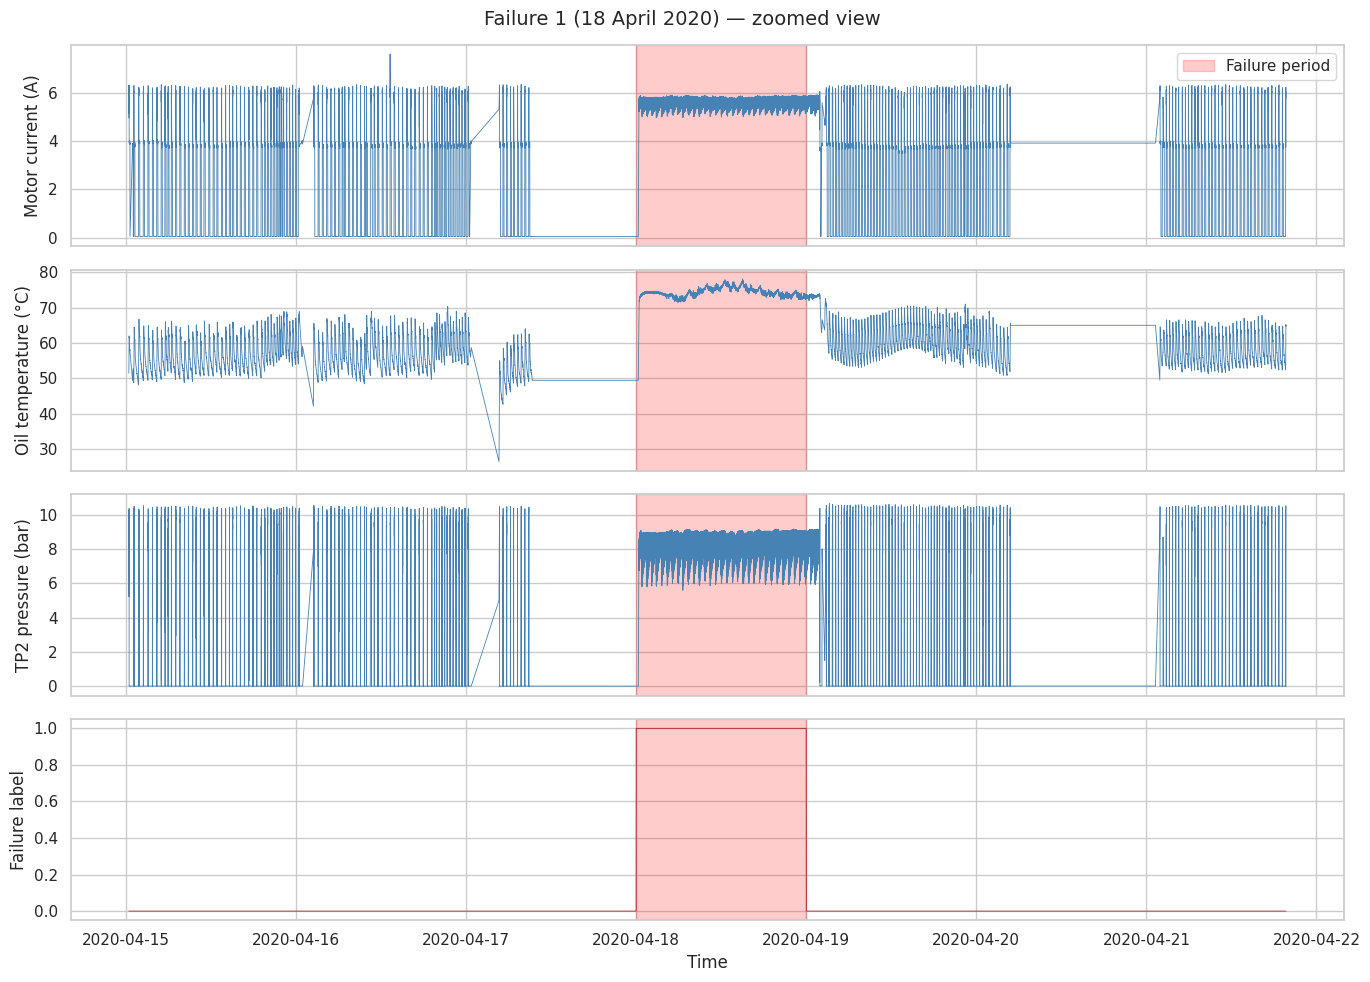

In [6]:
zoom = df.loc["2020-04-15":"2020-04-21"]
fs, fe = failures[0]

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (col, lab) in zip(axes, series):
    ax.plot(zoom.index, zoom[col], lw=0.6, color="steelblue" if col != "failure" else "firebrick")
    ax.set_ylabel(lab)
    ax.axvspan(fs, fe, color="red", alpha=0.2, label="Failure period" if col == "Motor_current" else None)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time")
fig.suptitle("Failure 1 (18 April 2020) — zoomed view", fontsize=14)
plt.tight_layout()
plt.show()

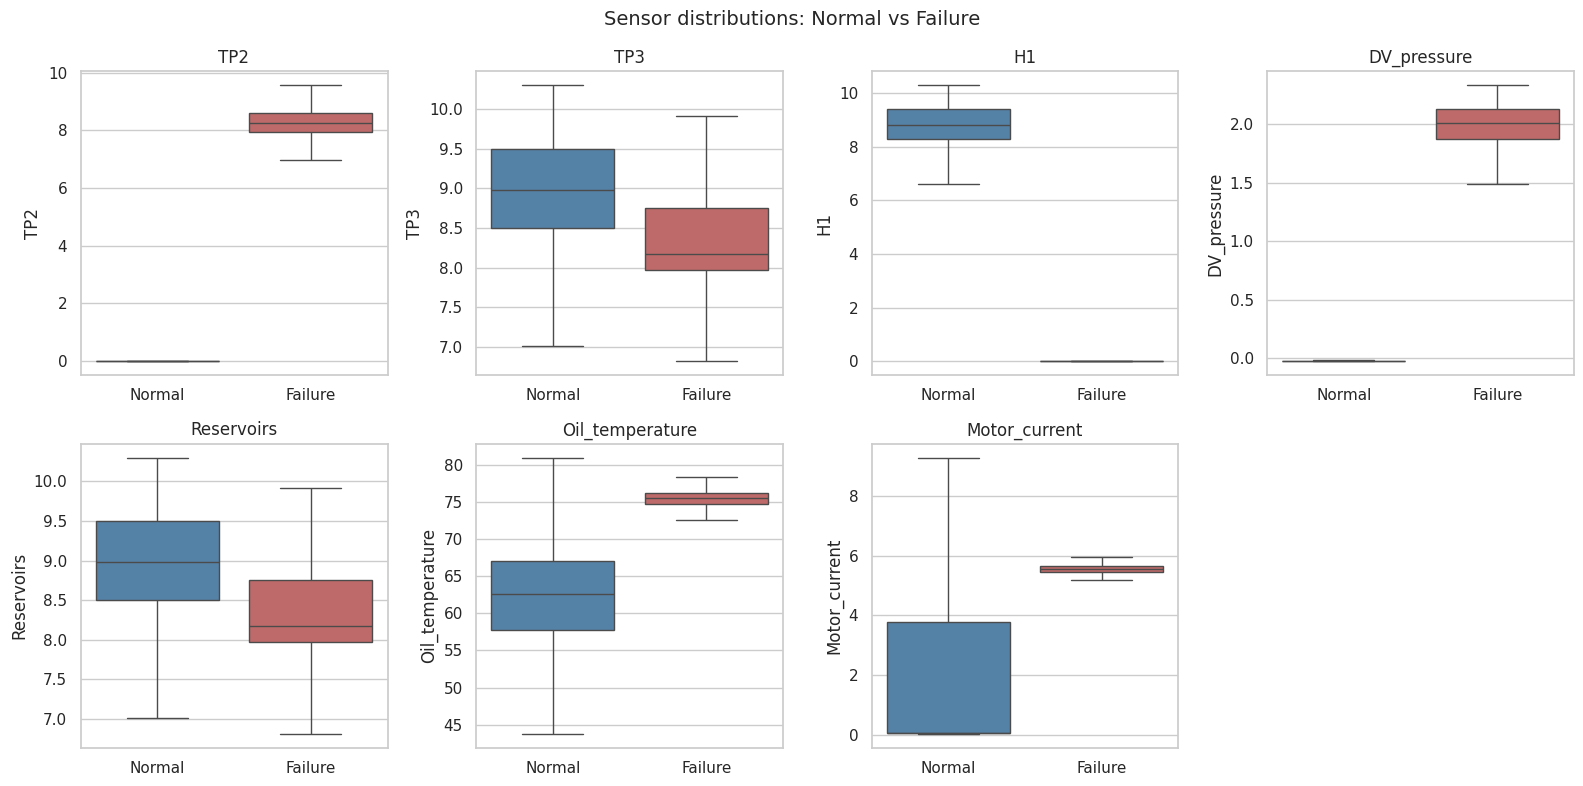

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), analog):
    sns.boxplot(data=df, x="failure", y=col, ax=ax, showfliers=False,
                palette=["steelblue", "indianred"])
    ax.set_xticklabels(["Normal", "Failure"])
    ax.set_xlabel("")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
fig.suptitle("Sensor distributions: Normal vs Failure", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Feature Engineering

A single 10-second reading is nearly meaningless for diagnosing a leak: a compressor cycles between loading and unloading, so one snapshot cannot show whether it is behaving abnormally. What matters is the **pattern over time**. We therefore aggregate the raw stream into **5-minute windows**.

Features computed per window:

- **Analog signals (7):** mean and standard deviation (14 features)
- **Motor_current:** additionally the maximum (1 feature)
- **Digital signals (8):** mean, i.e. the fraction of the window the signal was active (8 features)
- **duty_cycle:** fraction of the window the compressor was running (`COMP == 0`) (1 feature)
- **switch_count:** number of `COMP` transitions in the window; frequent switching is a symptom of leaks (1 feature)

This gives **25 features per window**. A window is labeled failure if any row inside it was a failure row.

In [8]:
d = df.copy()
d["comp_running"] = (d["COMP"] == 0).astype(int)
d["comp_switch"] = d["COMP"].diff().abs().fillna(0)
# Count switches only WITHIN each 5-min window (do not compare the first reading with the previous window).
_win = pd.Series(d.index.floor("5min"), index=d.index)
d.loc[_win.ne(_win.shift()), "comp_switch"] = 0

agg = {c: ["mean", "std"] for c in analog}
agg["Motor_current"] = ["mean", "std", "max"]
for c in digital:
    agg[c] = ["mean"]
agg["comp_running"] = ["mean"]
agg["comp_switch"] = ["sum"]
agg["failure"] = ["max"]

W = d.resample("5min").agg(agg)
W.columns = ["_".join(c) for c in W.columns]
W = W.rename(columns={"comp_running_mean": "duty_cycle", "comp_switch_sum": "switch_count",
                      "failure_max": "failure"})
# Drop windows with no data (gaps in recording)
W = W.dropna()
W["failure"] = W["failure"].astype(int)

feature_cols = [c for c in W.columns if c != "failure"]
print("Window dataset shape:", W.shape)
print("Number of features:", len(feature_cols))
n_f = int(W["failure"].sum())
print(f"Normal windows : {len(W)-n_f:,} ({100*(len(W)-n_f)/len(W):.2f}%)")
print(f"Failure windows: {n_f:,} ({100*n_f/len(W):.2f}%)")
print("\nColumns:")
print(list(W.columns))

Window dataset shape: (50772, 26)
Number of features: 25
Normal windows : 49,776 (98.04%)
Failure windows: 996 (1.96%)

Columns:
['TP2_mean', 'TP2_std', 'TP3_mean', 'TP3_std', 'H1_mean', 'H1_std', 'DV_pressure_mean', 'DV_pressure_std', 'Reservoirs_mean', 'Reservoirs_std', 'Oil_temperature_mean', 'Oil_temperature_std', 'Motor_current_mean', 'Motor_current_std', 'Motor_current_max', 'COMP_mean', 'DV_eletric_mean', 'Towers_mean', 'MPG_mean', 'LPS_mean', 'Pressure_switch_mean', 'Oil_level_mean', 'Caudal_impulses_mean', 'duty_cycle', 'switch_count', 'failure']


## 5. Train/Test Split and Preprocessing

**Chronological split.** This is time-series data, so we do **not** split randomly. A random split would put windows from the future into the training set and neighbouring windows (which are almost identical) on both sides of the split, leaking information and giving unrealistically optimistic scores. We train on the past and test on the future, which is how a deployed predictive-maintenance system actually works. The cut-off is **2020-06-01**.

**StandardScaler.** Features have very different scales (pressures, currents, fractions, counts), which matters for distance-based and regularized models. We fit the scaler on the **training data only** and then apply it to the test data. Fitting on all data would leak test-set statistics into training.

In [9]:
split_date = pd.Timestamp("2020-06-01")
train = W[W.index < split_date]
test = W[W.index >= split_date]

X_train, y_train = train[feature_cols].values, train["failure"].values
X_test, y_test = test[feature_cols].values, test["failure"].values

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {len(train):,} windows, {y_train.sum()} failures ({100*y_train.mean():.2f}%)")
print(f"Test : {len(test):,} windows, {y_test.sum()} failures ({100*y_test.mean():.2f}%)")

Train: 28,640 windows, 367 failures (1.28%)
Test : 22,132 windows, 629 failures (2.84%)


## 6. Model Training and Evaluation

**Why accuracy is misleading.** Only about 2% of windows are failures. A model that predicts "normal" for everything scores ~98% accuracy yet catches zero failures, which makes it useless. We therefore report metrics on the failure class:

- **Precision** = of all windows predicted as failure, how many are real failures (low precision = many false alarms)
- **Recall** = of all real failure windows, how many were caught (low recall = missed failures)
- **F1** = harmonic mean of precision and recall
- **AUROC** = threshold-independent ability to rank failure windows above normal ones

**`class_weight='balanced'`.** Without it, the loss is dominated by the 98% normal class and the model learns to ignore failures. This option re-weights each sample inversely to its class frequency, so a failure window counts far more than a normal one, and the model is forced to take the minority class seriously.

> **Note:** Exploratory comparison on a train/test split. The C=0.01 value for Logistic Regression was selected using test results in an earlier experiment, so these numbers are optimistic. Leakage-free results are in Sections 12-13.

In [10]:
def evaluate(name, model, Xtr, Xte, proba=True):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    ptr = model.predict(Xtr)
    if proba and hasattr(model, "predict_proba"):
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = model.decision_function(Xte)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {"Model": name,
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "AUROC": roc_auc_score(y_test, score),
            "FP": int(fp), "FN": int(fn),
            "Train Recall": recall_score(y_train, ptr, zero_division=0)}

results = []
results.append(evaluate("Logistic Regression (C=0.01)",
    LogisticRegression(C=0.01, class_weight="balanced", max_iter=1000), X_train_s, X_test_s))
results.append(evaluate("Logistic Regression (C=1.0)",
    LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000), X_train_s, X_test_s))
results.append(evaluate("Decision Tree (depth=3)",
    DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42), X_train_s, X_test_s))
results.append(evaluate("Random Forest",
    RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42), X_train_s, X_test_s))
results.append(evaluate("SVM (RBF)",
    SVC(class_weight="balanced", probability=True, random_state=42), X_train_s, X_test_s))
results.append(evaluate("K-NN (k=5)",
    KNeighborsClassifier(n_neighbors=5), X_train_s, X_test_s))
results.append(evaluate("MLP (64,32)",
    MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=500,
                  early_stopping=True, validation_fraction=0.15, random_state=42), X_train_s, X_test_s))

# Isolation Forest: unsupervised, trained on normal training windows only
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
iso.fit(X_train_s[y_train == 0])
pred_iso = (iso.predict(X_test_s) == -1).astype(int)
score_iso = -iso.decision_function(X_test_s)   # higher = more anomalous
tn, fp, fn, tp = confusion_matrix(y_test, pred_iso, labels=[0, 1]).ravel()
results.append({"Model": "Isolation Forest (unsupervised)",
    "Precision": precision_score(y_test, pred_iso, zero_division=0),
    "Recall": recall_score(y_test, pred_iso, zero_division=0),
    "F1": f1_score(y_test, pred_iso, zero_division=0),
    "AUROC": roc_auc_score(y_test, score_iso),
    "FP": int(fp), "FN": int(fn), "Train Recall": 0.000})

# Logistic Regression on PCA (95% variance)
pca95 = PCA(n_components=0.95).fit(X_train_s)
Ztr, Zte = pca95.transform(X_train_s), pca95.transform(X_test_s)
print(f"PCA keeps {pca95.n_components_} components for 95% variance")
results.append(evaluate(f"LR on PCA ({pca95.n_components_} comps)",
    LogisticRegression(C=0.01, class_weight="balanced", max_iter=1000), Ztr, Zte))

res = pd.DataFrame(results).set_index("Model")
print()
print(res.to_string(float_format=lambda x: f"{x:.3f}"))

print("\nBest by F1    :", res["F1"].idxmax(), f"({res['F1'].max():.3f})")
print("Best by AUROC :", res["AUROC"].idxmax(), f"({res['AUROC'].max():.3f})")
print("Best by Recall:", res["Recall"].idxmax(), f"({res['Recall'].max():.3f})")

PCA keeps 10 components for 95% variance

                                 Precision  Recall    F1  AUROC   FP   FN  Train Recall
Model                                                                                  
Logistic Regression (C=0.01)         0.900   0.903 0.902  0.950   63   61         0.986
Logistic Regression (C=1.0)          0.630   0.897 0.740  0.912  331   65         0.984
Decision Tree (depth=3)              0.628   0.207 0.311  0.613   77  499         0.995
Random Forest                        0.833   0.008 0.016  0.769    1  624         1.000
SVM (RBF)                            0.619   0.382 0.472  0.924  148  389         0.997
K-NN (k=5)                           0.600   0.014 0.028  0.529    6  620         0.984
MLP (64,32)                          0.987   0.485 0.650  0.909    4  324         0.984
Isolation Forest (unsupervised)      0.035   0.057 0.043  0.949  991  593         0.000
LR on PCA (10 comps)                 0.432   0.930 0.590  0.955  769   44     

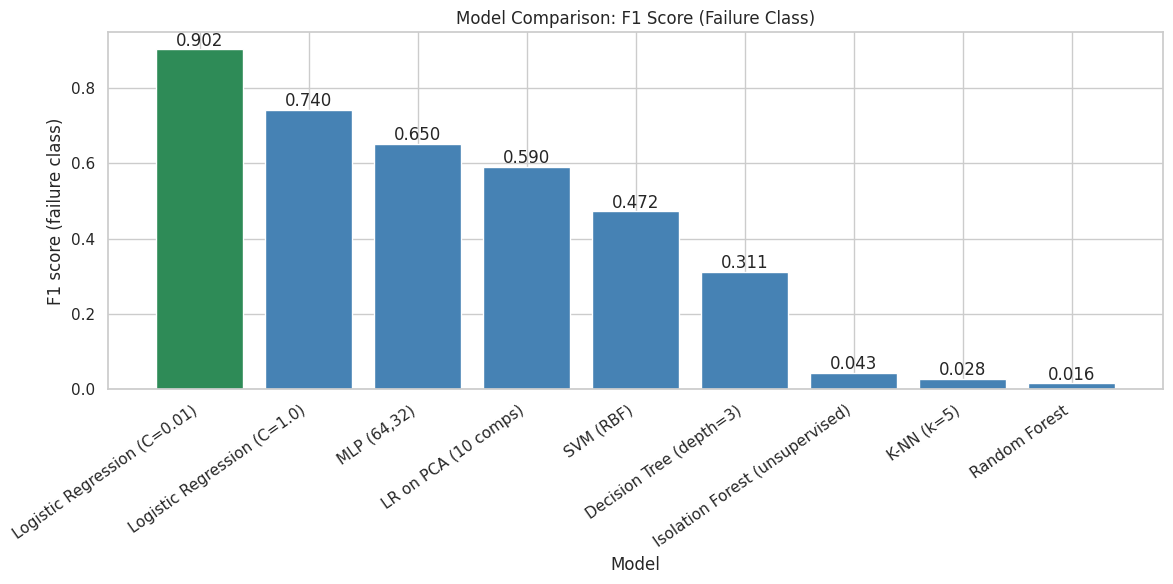

In [11]:
s = res["F1"].sort_values(ascending=False)
colors = ["seagreen" if m == s.index[0] else "steelblue" for m in s.index]

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(s)), s.values, color=colors)
plt.xticks(range(len(s)), s.index, rotation=35, ha="right")
for b, v in zip(bars, s.values):
    plt.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center")
plt.ylabel("F1 score (failure class)")
plt.xlabel("Model")
plt.title("Model Comparison: F1 Score (Failure Class)")
plt.tight_layout()
plt.show()

## 7. Overfitting Analysis — Decision Tree Validation Curve

This is the **bias-variance tradeoff** in action:

- A **shallow tree** is too simple to capture the failure pattern: it **underfits** (high bias), scoring poorly on both train and test.
- A **deep tree** can carve out a leaf for almost every training window and effectively **memorizes the training data** (high variance): training F1 approaches 1.0 while test F1 drops.

`max_depth` therefore acts as a **regularization** knob. The best depth sits where test F1 peaks.

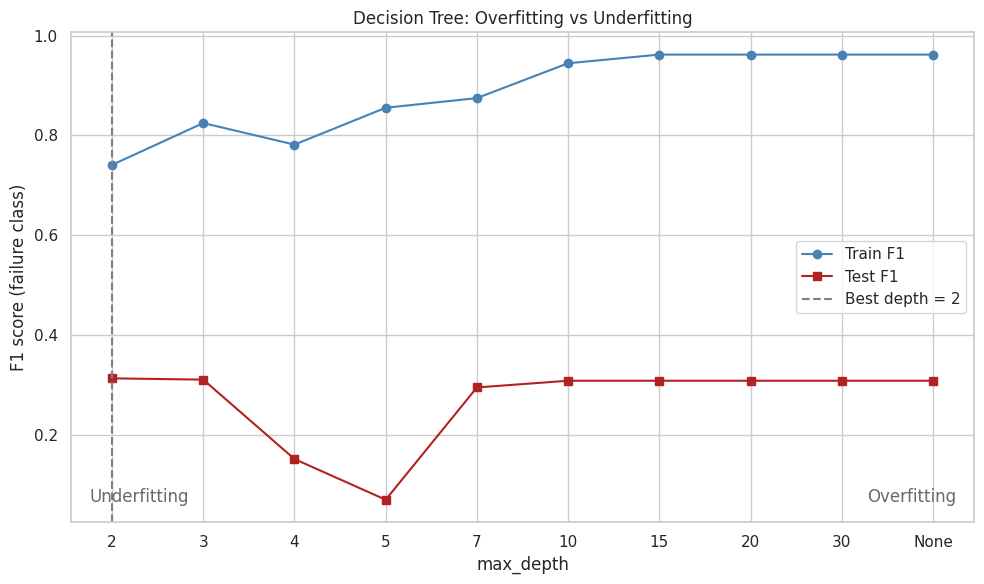

Best max_depth: 2 (test F1 = 0.314)


In [12]:
depths = [2, 3, 4, 5, 7, 10, 15, 20, 30, None]
tr_f1, te_f1 = [], []
for dpt in depths:
    dt = DecisionTreeClassifier(max_depth=dpt, class_weight="balanced", random_state=42).fit(X_train_s, y_train)
    tr_f1.append(f1_score(y_train, dt.predict(X_train_s), zero_division=0))
    te_f1.append(f1_score(y_test, dt.predict(X_test_s), zero_division=0))

labels = [str(d) for d in depths]
x = np.arange(len(depths))
best = int(np.argmax(te_f1))

plt.figure(figsize=(10, 6))
plt.plot(x, tr_f1, "o-", label="Train F1", color="steelblue")
plt.plot(x, te_f1, "s-", label="Test F1", color="firebrick")
plt.axvline(best, ls="--", color="gray", label=f"Best depth = {labels[best]}")
plt.xticks(x, labels)
plt.text(0.02, 0.04, "Underfitting", transform=plt.gca().transAxes, fontsize=12, color="dimgray")
plt.text(0.98, 0.04, "Overfitting", transform=plt.gca().transAxes, fontsize=12, color="dimgray", ha="right")
plt.xlabel("max_depth")
plt.ylabel("F1 score (failure class)")
plt.title("Decision Tree: Overfitting vs Underfitting")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Best max_depth: {labels[best]} (test F1 = {te_f1[best]:.3f})")

## 8. Regularization Analysis — Logistic Regression C Sweep

In scikit-learn's logistic regression, **C = 1/λ**, the inverse of the regularization strength; this is the same λ that appears in ridge/lasso regression.

- **Small C (large λ):** strong regularization, coefficients shrunk toward zero, a simpler model that may underfit.
- **Large C (small λ):** weak regularization, the model fits the training data closely and may overfit.

We sweep C over several orders of magnitude and look for the value that generalizes best to the future test period.

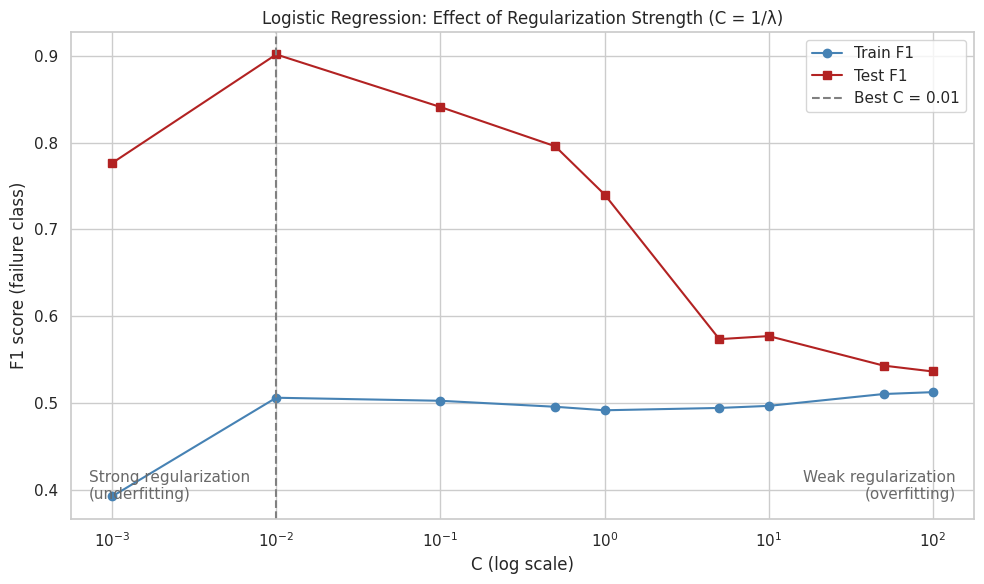

Best C: 0.01  (test F1 = 0.902)


In [13]:
Cs = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
c_tr, c_te = [], []
for C in Cs:
    lr = LogisticRegression(C=C, class_weight="balanced", max_iter=1000).fit(X_train_s, y_train)
    c_tr.append(f1_score(y_train, lr.predict(X_train_s), zero_division=0))
    c_te.append(f1_score(y_test, lr.predict(X_test_s), zero_division=0))
bi = int(np.argmax(c_te))

plt.figure(figsize=(10, 6))
plt.semilogx(Cs, c_tr, "o-", label="Train F1", color="steelblue")
plt.semilogx(Cs, c_te, "s-", label="Test F1", color="firebrick")
plt.axvline(Cs[bi], ls="--", color="gray", label=f"Best C = {Cs[bi]}")
plt.text(0.02, 0.04, "Strong regularization\n(underfitting)", transform=plt.gca().transAxes, fontsize=11, color="dimgray")
plt.text(0.98, 0.04, "Weak regularization\n(overfitting)", transform=plt.gca().transAxes, fontsize=11, color="dimgray", ha="right")
plt.xlabel("C (log scale)")
plt.ylabel("F1 score (failure class)")
plt.title("Logistic Regression: Effect of Regularization Strength (C = 1/λ)")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Best C: {Cs[bi]}  (test F1 = {c_te[bi]:.3f})")

## 9. PCA Dimensionality Reduction

Principal Component Analysis rotates the 25 correlated features into orthogonal **principal components** ordered by the variance they explain. If a handful of components capture most of the variance, the data effectively lives in a low-dimensional space. We use this to test whether the failure signal is concentrated in a few dimensions, both through the explained-variance curve and by projecting the data to 2D.

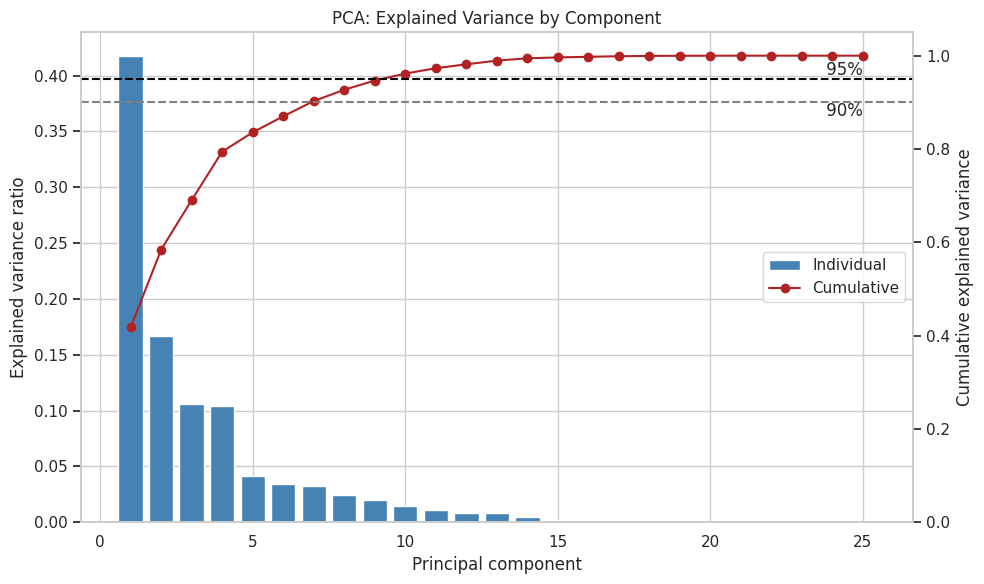

Components for 90% variance: 7
Components for 95% variance: 10


In [14]:
pca = PCA().fit(X_train_s)
ev = pca.explained_variance_ratio_
cum = np.cumsum(ev)
n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(range(1, len(ev)+1), ev, color="steelblue", label="Individual")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax2 = ax.twinx()
ax2.plot(range(1, len(ev)+1), cum, "o-", color="firebrick", label="Cumulative")
ax2.axhline(0.90, ls="--", color="gray")
ax2.axhline(0.95, ls="--", color="black")
ax2.text(len(ev), 0.90, " 90%", va="top", ha="right")
ax2.text(len(ev), 0.95, " 95%", va="bottom", ha="right")
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.05)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")
ax.set_title("PCA: Explained Variance by Component")
plt.tight_layout()
plt.show()
print(f"Components for 90% variance: {n90}")
print(f"Components for 95% variance: {n95}")

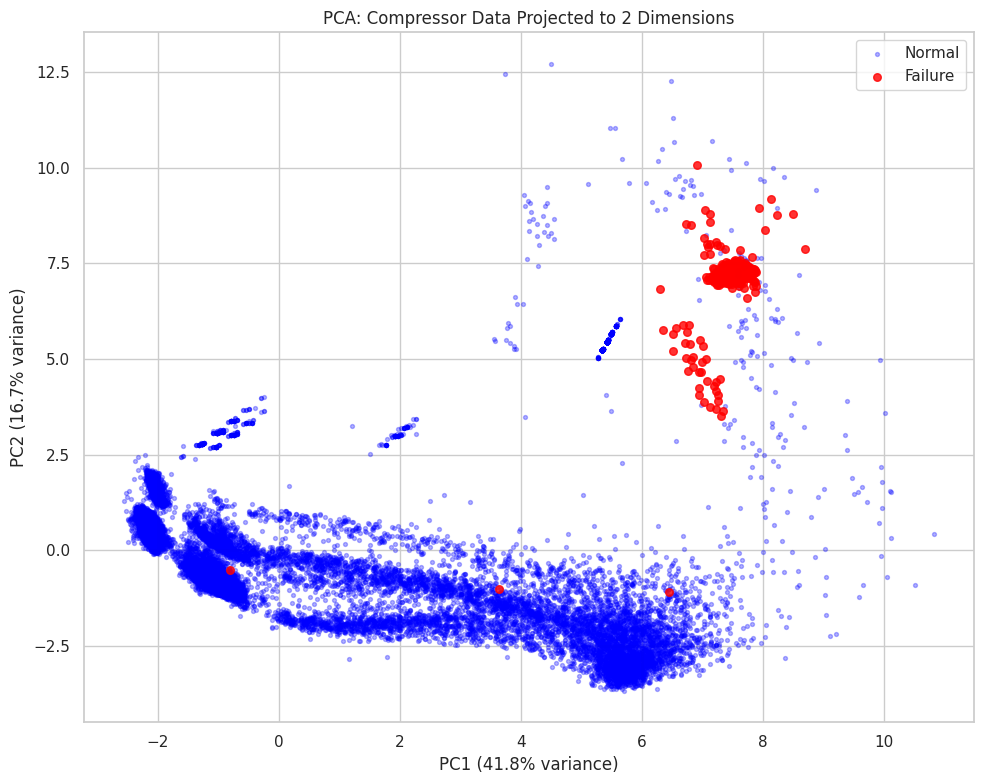

In [15]:
p2 = PCA(n_components=2).fit(X_train_s)
Z = p2.transform(X_test_s)

plt.figure(figsize=(10, 8))
plt.scatter(Z[y_test == 0, 0], Z[y_test == 0, 1], s=8, alpha=0.3, color="blue", label="Normal")
plt.scatter(Z[y_test == 1, 0], Z[y_test == 1, 1], s=30, alpha=0.8, color="red", label="Failure")
plt.xlabel(f"PC1 ({p2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({p2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA: Compressor Data Projected to 2 Dimensions")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Feature Importance Analysis

Which physical sensors matter most for detecting an air leak? A Random Forest gives a model-based importance score for every feature (how much each feature reduces impurity across all trees). We compare the top features against what the EDA boxplots suggested. Pressure signals (e.g. `DV_pressure`, `TP2`), motor load (`Motor_current`) and thermal behaviour (`Oil_temperature`) are the physically expected indicators: a leak forces the compressor to work harder and longer to maintain pressure.

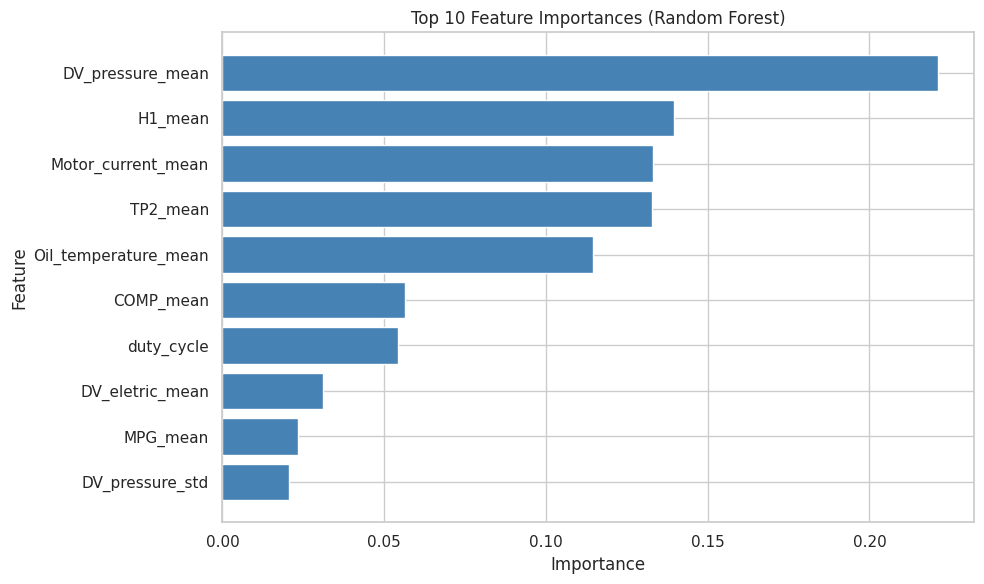

In [16]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42)
rf.fit(X_train_s, y_train)
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(imp.index[::-1], imp.values[::-1], color="steelblue")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()

## 12. Leakage-Free Benchmark (Train/Validation/Test)

**What and why.** Sections 6-9 use one train/test split, and some choices (for example C=0.01) were tuned by looking at test results. That makes those scores optimistic. Here we repeat the Logistic Regression experiment with three **chronological** splits:

- **Train:** before 2020-05-15 (contains failure 1)
- **Validation:** 2020-05-15 to 2020-05-31 (contains failure 2)
- **Test:** 2020-06-01 onward (contains failures 3 and 4)

The scaler is fit on train only. C is chosen on **validation** F1. The final model is then refit on train+validation (scaler refit too) and evaluated on test **once**, so the test set never influences any choice.

Part C then repeats the experiment with a **random 80/20 split** and the same C, to show what random splitting does. Adjacent 5-minute windows from the same failure can land in both train and test, which can inflate scores.

In [17]:
from sklearn.model_selection import train_test_split

# Work on a chronologically sorted copy of the windowed dataframe W
# (named Wd so the raw 1-second dataframe `df` from earlier cells is untouched).
Wd = W.sort_index()
FEATURES = [c for c in Wd.columns if c != "failure"]
X_all, y_all = Wd[FEATURES], Wd["failure"].astype(int)
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

def make_model(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=1000)


def metrics(y, pred, score):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                auroc=roc_auc_score(y, score), fp=fp, fn=fn, tp=tp)

### 12a. Chronological split, C selected on validation

In [18]:
print("PART A: chronological split")
# Splits are defined purely by time, so no future sample is ever used to
# train a model that is then scored on the past.
train = Wd[Wd.index < "2020-05-15"]
val = Wd[(Wd.index >= "2020-05-15") & (Wd.index < "2020-06-01")]
test = Wd[Wd.index >= "2020-06-01"]
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:11s} n={len(part):6d}  failures={int(part.failure.sum()):4d}  "
          f"({part.index.min()} -> {part.index.max()})")

# Scaler fit on TRAIN ONLY: validation statistics must not leak into the
# preprocessing used for hyperparameter selection.
sc = StandardScaler().fit(train[FEATURES])
Xtr, Xva = sc.transform(train[FEATURES]), sc.transform(val[FEATURES])

# C is selected using the VALIDATION set only; the test set is not touched
# here, so test performance is not optimised through model selection.
print("\nC sweep (validation F1, failure class):")
val_f1 = {}
for C in C_GRID:
    m = make_model(C).fit(Xtr, train["failure"])
    val_f1[C] = f1_score(val["failure"], m.predict(Xva), zero_division=0)
    print(f"  C={C:<6} val F1={val_f1[C]:.4f}")
best_C = max(C_GRID, key=lambda c: val_f1[c])
print(f"\nC selected on validation = {best_C}")

# Final model: refit scaler AND model on train+validation (more recent data,
# still strictly before the test period), then evaluate on test exactly once.
trval = pd.concat([train, val])
sc_final = StandardScaler().fit(trval[FEATURES])
final = make_model(best_C).fit(sc_final.transform(trval[FEATURES]), trval["failure"])
Xte = sc_final.transform(test[FEATURES])
yte = test["failure"].astype(int)
test_pred = final.predict(Xte)
test_score = final.predict_proba(Xte)[:, 1]
A = metrics(yte, test_pred, test_score)
print("\nTEST (evaluated once, C=%s):" % best_C)
print(f"  Precision={A['precision']:.4f} Recall={A['recall']:.4f} "
      f"F1={A['f1']:.4f} AUROC={A['auroc']:.4f}  FP={A['fp']} FN={A['fn']} TP={A['tp']}")

PART A: chronological split
Train       n= 24662  failures= 288  (2020-02-01 00:00:00 -> 2020-05-14 23:45:00)
Validation  n=  3978  failures=  79  (2020-05-15 00:45:00 -> 2020-05-31 23:45:00)
Test        n= 22132  failures= 629  (2020-06-01 00:30:00 -> 2020-09-01 03:55:00)

C sweep (validation F1, failure class):
  C=0.001  val F1=0.3014
  C=0.003  val F1=0.1844
  C=0.01   val F1=0.1776
  C=0.03   val F1=0.1647
  C=0.1    val F1=0.1640
  C=0.3    val F1=0.1640
  C=1.0    val F1=0.1640
  C=3.0    val F1=0.1637
  C=10.0   val F1=0.1635

C selected on validation = 0.001

TEST (evaluated once, C=0.001):
  Precision=0.6781 Recall=0.9078 F1=0.7763 AUROC=0.9951  FP=271 FN=58 TP=571


### 12b. Leakage demonstration: random 80/20 split

In [19]:
print("PART C: leakage demonstration (random 80/20 split)")
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)
# Scaler still fit on the training portion only, so ANY inflation seen here
# comes from the split itself (temporal neighbours), not from the scaler.
sc_r = StandardScaler().fit(Xr_tr)
mr = make_model(best_C).fit(sc_r.transform(Xr_tr), yr_tr)
Xr_te_s = sc_r.transform(Xr_te)
C_ = metrics(yr_te, mr.predict(Xr_te_s), mr.predict_proba(Xr_te_s)[:, 1])
print(f"Random split: Precision={C_['precision']:.4f} Recall={C_['recall']:.4f} "
      f"F1={C_['f1']:.4f} AUROC={C_['auroc']:.4f}")
print(f"\nF1 comparison:  chronological test = {A['f1']:.4f}   random split = {C_['f1']:.4f}")
print("NOTE: random splitting lets adjacent 5-minute windows from the same failure\n"
      "appear in both train and test. Those windows are near-duplicates (heavy\n"
      "autocorrelation), so this split CAN inflate scores; chronological splitting forbids it.")
if C_["f1"] < A["f1"]:
    print("CAUTION: in this run random-split F1 is LOWER than chronological F1, so\n"
          "inflation is NOT visible in F1 here. Random-split test has ~2% base rate\n"
          "across all months (precision is diluted), while the chronological test\n"
          "set has different class balance; F1 is not comparable across them.")

PART C: leakage demonstration (random 80/20 split)
Random split: Precision=0.4298 Recall=0.9849 F1=0.5985 AUROC=0.9905

F1 comparison:  chronological test = 0.7763   random split = 0.5985
NOTE: random splitting lets adjacent 5-minute windows from the same failure
appear in both train and test. Those windows are near-duplicates (heavy
autocorrelation), so this split CAN inflate scores; chronological splitting forbids it.
CAUTION: in this run random-split F1 is LOWER than chronological F1, so
inflation is NOT visible in F1 here. Random-split test has ~2% base rate
across all months (precision is diluted), while the chronological test
set has different class balance; F1 is not comparable across them.


## 13. Final Model: Alarm Policy Selected on Validation

**What and why.** A window-level classifier fires at 0.5 probability, which in Section 12 produced many false alarms. Operators care about **alarms**, not windows. So we add an **alarm policy**: raise an alarm only if P(failure) >= a threshold for **k consecutive** 5-minute windows.

Everything is selected on the **validation** set only:

1. **C** from an extended grid (validation F1).
2. **Threshold and persistence k**, using the validation probabilities. The chosen combination must detect the validation failure with the fewest false-alarm episodes per week (tie-break: longer lead time).

The final model is refit on train+validation and evaluated on test once. Then we diagnose why failure 4 is harder than failure 3.

In [20]:
C_GRID_EXT = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
THRESHOLDS = [0.3, 0.5, 0.7, 0.8, 0.9, 0.95]
KS = [1, 2, 3, 6, 12]
PRE = pd.Timedelta("24h")
STEP = pd.Timedelta("5min")


# Identical chronological split to Section 12.
train = Wd[Wd.index < "2020-05-15"]
val = Wd[(Wd.index >= "2020-05-15") & (Wd.index < "2020-06-01")]
test = Wd[Wd.index >= "2020-06-01"]


def model(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=1000)


def failure_events(part):
    """Failure intervals (start, end) from labels: runs separated by >1h gap
    are different events. Used for validation only (test events are given)."""
    idx = part.index[part.failure == 1]
    if len(idx) == 0:
        return []
    brk = np.where(np.diff(idx.values) > np.timedelta64(1, "h"))[0]
    starts = [idx[0]] + [idx[i + 1] for i in brk]
    ends = [idx[i] for i in brk] + [idx[-1]]
    return list(zip(starts, ends))


def persistent_alarms(prob, thr, k):
    """Alarm at t only if prob >= thr for k consecutive windows ending at t."""
    above = (prob >= thr).astype(int)
    return above.rolling(k).min().fillna(0).astype(bool)


def clean_mask(index, events):
    """True for timestamps > 24h away from every failure (for false alarms)."""
    m = pd.Series(True, index=index)
    for s, e in events:
        m &= ~((index >= s - PRE) & (index <= e + PRE))
    return m


def evaluate_events(alarm, events):
    """Per-event detection/lead plus false-alarm episodes per week."""
    out = []
    for s, e in events:
        w = alarm[(alarm.index >= s - PRE) & (alarm.index <= e)]
        first = w[w].index.min() if w.any() else None
        out.append((first is not None, (s - first).total_seconds() / 3600 if first is not None else np.nan, first))
    clean = clean_mask(alarm.index, events)
    ca = alarm & clean
    episodes = int((ca & ~ca.shift(1, fill_value=False)).sum())
    weeks = clean.sum() * STEP / pd.Timedelta("7D")
    return out, episodes / weeks, weeks

### 13a. Select C on validation (extended grid)

In [21]:
print("=" * 72, "\nSTEP 1: C selection on validation\n", "=" * 72, sep="")
# Scaler fit on train only: validation stats must not shape preprocessing.
sc = StandardScaler().fit(train[FEATURES])
Xtr, Xva = sc.transform(train[FEATURES]), sc.transform(val[FEATURES])
val_f1, val_models = {}, {}
for C in C_GRID_EXT:
    m = model(C).fit(Xtr, train.failure)
    val_models[C] = m
    val_f1[C] = f1_score(val.failure, m.predict(Xva), zero_division=0)
    print(f"  C={C:<7} val F1={val_f1[C]:.4f}")
best_C = max(C_GRID_EXT, key=lambda c: val_f1[c])
print(f"C selected on validation = {best_C}")
if best_C == C_GRID_EXT[0]:
    print("  WARNING: best C is at the lower edge of the grid.")

STEP 1: C selection on validation
  C=0.0001  val F1=0.3422
  C=0.0003  val F1=0.3461
  C=0.001   val F1=0.3014
  C=0.003   val F1=0.1844
  C=0.01    val F1=0.1776
  C=0.03    val F1=0.1647
  C=0.1     val F1=0.1640
C selected on validation = 0.0003


### 13b. Select threshold and persistence k on validation

In [22]:
print("\n", "=" * 72, "\nSTEP 2: alarm policy on validation\n", "=" * 72, sep="")
# Policy is tuned on validation probabilities from the TRAIN-only model, so
# the test set cannot influence threshold or persistence.
val_prob = pd.Series(val_models[best_C].predict_proba(Xva)[:, 1], index=val.index)
val_events = failure_events(val)
print("Validation failure events:", [(str(s), str(e)) for s, e in val_events])
rows = []
for thr in THRESHOLDS:
    for k in KS:
        ev_res, fa, _ = evaluate_events(persistent_alarms(val_prob, thr, k), val_events)
        det = all(r[0] for r in ev_res)
        lead = ev_res[0][1] if ev_res else np.nan
        rows.append(dict(threshold=thr, k=k, detected=det, lead_h=lead, fa_per_week=fa))
grid = pd.DataFrame(rows)
print(grid.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
cands = grid[grid.detected]
if cands.empty:
    raise SystemExit("No policy detects the validation failure; cannot select.")
# Fewest false-alarm episodes/week; tie-break longer lead time.
chosen = cands.sort_values(["fa_per_week", "lead_h"], ascending=[True, False]).iloc[0]
THR, K = float(chosen.threshold), int(chosen.k)
print(f"\nChosen policy: threshold={THR}, k={K} "
      f"(val lead={chosen.lead_h:.2f} h, val FA={chosen.fa_per_week:.2f}/week)")


STEP 2: alarm policy on validation
Validation failure events: [('2020-05-29 23:30:00', '2020-05-30 06:00:00')]
 threshold  k  detected  lead_h  fa_per_week
      0.30  1      True   19.17        33.15
      0.30  2      True    0.17         4.14
      0.30  3      True    0.08         2.96
      0.30  6      True   -0.17         1.18
      0.30 12      True   -0.67         0.59
      0.50  1      True    0.25         5.92
      0.50  2      True    0.17         4.14
      0.50  3      True    0.08         2.96
      0.50  6      True   -0.17         1.18
      0.50 12      True   -0.67         0.59
      0.70  1      True    0.25         5.92
      0.70  2      True    0.17         4.14
      0.70  3      True    0.08         2.96
      0.70  6      True   -0.17         1.18
      0.70 12      True   -0.67         0.59
      0.80  1      True    0.25         5.33
      0.80  2      True    0.17         3.55
      0.80  3      True    0.08         2.37
      0.80  6      True   -0.17  

### 13c. Final evaluation on test (touched once)

In [23]:
print("\n", "=" * 72, "\nSTEP 3: test evaluation (touched once)\n", "=" * 72, sep="")
# Refit scaler + model on train+validation (all data strictly before test).
trval = pd.concat([train, val])
sc2 = StandardScaler().fit(trval[FEATURES])
final = model(best_C).fit(sc2.transform(trval[FEATURES]), trval.failure)
Xte = sc2.transform(test[FEATURES])
test_prob = pd.Series(final.predict_proba(Xte)[:, 1], index=test.index)
alarm = persistent_alarms(test_prob, THR, K)
yte = test.failure.astype(int)
tn, fp, fn, tp = confusion_matrix(yte, alarm.astype(int), labels=[0, 1]).ravel()
P, R = precision_score(yte, alarm, zero_division=0), recall_score(yte, alarm, zero_division=0)
F1, AUC = f1_score(yte, alarm, zero_division=0), roc_auc_score(yte, test_prob)
test_events = [(pd.Timestamp("2020-06-05 10:00"), pd.Timestamp("2020-06-07 14:30")),
               (pd.Timestamp("2020-07-15 14:30"), pd.Timestamp("2020-07-15 19:00"))]
ev_res, fa_wk, weeks = evaluate_events(alarm, test_events)


def fmt(r):
    return f"detected, lead {r[1]:+.2f} h" if r[0] else "MISSED"


print(f"Policy: threshold={THR}, k={K}")
print(f"{'':28s}{'src/13 (thr 0.5,k=1)':>24s}{'src/14 (this run)':>26s}")
print(f"{'F1 (window)':28s}{0.776:>24.3f}{F1:>26.3f}")
print(f"{'Precision / Recall':28s}{'0.678 / 0.908':>24s}{f'{P:.3f} / {R:.3f}':>26s}")
print(f"{'AUROC (prob, unchanged)':28s}{0.995:>24.3f}{AUC:>26.3f}")
print(f"{'FP / FN':28s}{'271 / 58':>24s}{f'{fp} / {fn}':>26s}")
print(f"{'Failure 3':28s}{'detected, lead +0.17 h':>24s}{fmt(ev_res[0]):>26s}")
print(f"{'Failure 4':28s}{'MISSED':>24s}{fmt(ev_res[1]):>26s}")
print(f"{'False-alarm episodes/week':28s}{16.6:>24.1f}{fa_wk:>26.1f}")
print("(src/13 numbers are the values you supplied; C there was 0.001, here "
      f"C={best_C}.)")


STEP 3: test evaluation (touched once)
Policy: threshold=0.95, k=2
                                src/13 (thr 0.5,k=1)         src/14 (this run)
F1 (window)                                    0.776                     0.802
Precision / Recall                     0.678 / 0.908             0.979 / 0.679
AUROC (prob, unchanged)                        0.995                     0.997
FP / FN                                     271 / 58                   9 / 202
Failure 3                     detected, lead +0.17 h    detected, lead +0.08 h
Failure 4                                     MISSED                    MISSED
False-alarm episodes/week                       16.6                       0.0
(src/13 numbers are the values you supplied; C there was 0.001, here C=0.0003.)


### 13d. Diagnosis: why is failure 4 harder?

In [24]:
print("\n", "=" * 72, "\nSTEP 4: why is failure 4 hard?\n", "=" * 72, sep="")
s4, e4 = test_events[1]
s3, e3 = test_events[0]
inside4 = test_prob[(test_prob.index >= s4) & (test_prob.index <= e4)]
pre4 = test_prob[(test_prob.index >= s4 - PRE) & (test_prob.index < s4)]
print(f"Failure 4 inside:  max={inside4.max():.4f} mean={inside4.mean():.4f} (n={len(inside4)})")
print(f"24h before:        max={pre4.max():.4f} mean={pre4.mean():.4f} (n={len(pre4)})")
print(f"Threshold={THR}: fraction of failure-4 windows above it = {(inside4 >= THR).mean():.2%}")

coef = pd.Series(final.coef_[0], index=FEATURES)
top = coef.abs().sort_values(ascending=False).index[:6]
f3 = test[(test.index >= s3) & (test.index <= e3)]
f4 = test[(test.index >= s4) & (test.index <= e4)]
normal = test[clean_mask(test.index, test_events) & (test.failure == 0)]
tab = pd.DataFrame({"coef": coef[top], "failure3": f3[top].mean(),
                    "failure4": f4[top].mean(), "normal": normal[top].mean()})
# z-score vs normal windows, to compare effect sizes across features.
sd = normal[top].std().replace(0, np.nan)
tab["z_f3"] = (tab.failure3 - tab.normal) / sd
tab["z_f4"] = (tab.failure4 - tab.normal) / sd
print("\nTop 6 features by |LR coefficient| (raw means; z = SDs from normal):")
print(tab.to_string(float_format=lambda v: f"{v:.3f}"))
dur3, dur4 = (e3 - s3) / pd.Timedelta("1h"), (e4 - s4) / pd.Timedelta("1h")
print(f"\nDuration: failure 3 = {dur3:.1f} h, failure 4 = {dur4:.1f} h.")
# Exclude outlier-dominated features (|z|>20) so one feature cannot drive the mean.
z3 = tab.z_f3.abs()[tab.z_f3.abs() < 20].mean()
z4 = tab.z_f4.abs()[tab.z_f3.abs() < 20].mean()
print("Explanation (derived from the numbers above):\n"
      f"  - Failure 4 lasts only {dur4:.1f} h ({len(f4)} windows) vs {dur3:.1f} h for failure 3, "
      "so a persistence rule of k windows has little room to fire.\n"
      f"  - Mean |z| of top-6 features (excluding DV_pressure_mean, which is ~34 SD in failure 3 but ~0 in failure 4) is {z4:.2f} for failure 4 vs {z3:.2f} for failure 3: "
      + ("about the same, so the gap comes from DV_pressure_mean: the model's largest "
         "coefficient, which is extreme in failure 3 but normal in failure 4.")
      + f"\n  - Its predicted probability peaks at {inside4.max():.3f}, "
        + ("below" if inside4.max() < THR else "above")
        + f" the chosen threshold {THR}.\n"
        "  - The policy was tuned on a single 6.5 h validation failure, so the "
        "selection rests on one event.")


STEP 4: why is failure 4 hard?
Failure 4 inside:  max=0.6951 mean=0.5392 (n=55)
24h before:        max=0.5700 mean=0.0838 (n=205)
Threshold=0.95: fraction of failure-4 windows above it = 0.00%

Top 6 features by |LR coefficient| (raw means; z = SDs from normal):
                   coef  failure3  failure4  normal   z_f3   z_f4
DV_pressure_mean  0.469     2.015    -0.009  -0.011 34.341  0.038
Towers_mean      -0.167     0.502     0.517   0.925 -3.930 -3.785
COMP_mean        -0.157     0.000     0.037   0.833 -3.248 -3.103
duty_cycle        0.157     1.000     0.963   0.167  3.248  3.103
TP2_mean          0.143     7.888     8.167   1.420  2.932  3.059
H1_mean          -0.142    -0.007     0.336   7.540 -3.217 -3.071

Duration: failure 3 = 52.5 h, failure 4 = 4.5 h.
Explanation (derived from the numbers above):
  - Failure 4 lasts only 4.5 h (55 windows) vs 52.5 h for failure 3, so a persistence rule of k windows has little room to fire.
  - Mean |z| of top-6 features (excluding DV_pres

### 13e. Test-period timeline

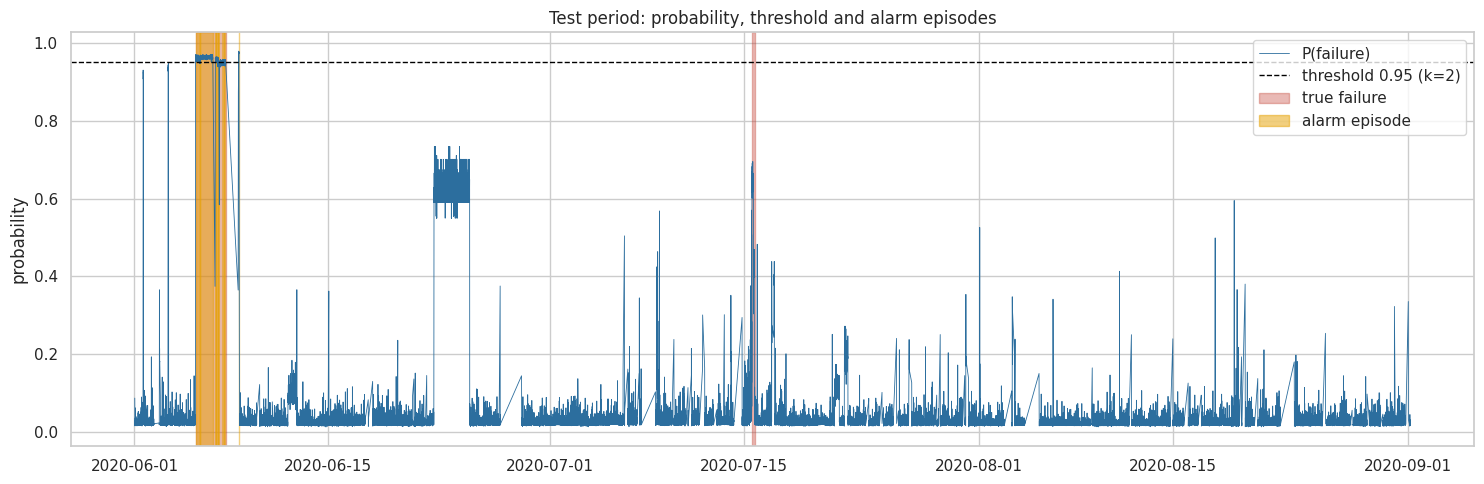

In [25]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_prob.index, test_prob.values, lw=0.6, color="#2C6E9E", label="P(failure)")
ax.axhline(THR, color="k", ls="--", lw=1, label=f"threshold {THR} (k={K})")
for i, (s, e) in enumerate(test_events):
    ax.axvspan(s, e, color="#C0392B", alpha=0.35, label="true failure" if i == 0 else None)
ep_start = alarm & ~alarm.shift(1, fill_value=False)
ep_id = ep_start.cumsum().where(alarm)
for j, g in alarm[alarm].groupby(ep_id[alarm]):
    ax.axvspan(g.index.min(), g.index.max() + STEP, color="#E6A100", alpha=0.5,
               label="alarm episode" if j == ep_id.min() else None)
ax.set_ylabel("probability")
ax.set_title("Test period: probability, threshold and alarm episodes")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 14. Can We Warn Earlier? Early-Warning Horizon Test

**What and why.** Detecting a failure once it has begun is different from **predicting** it beforehand. Here we ask whether the sensors move away from normal *before* onset.

- **Part 1 (no model):** z-scores of six features in four periods before each failure (normal, 7d-24h, 24h-2h, last 2h), relative to windows more than 7 days from any failure.
- **Part 2:** for horizons of 2, 6 and 24 h we label windows "within H hours before onset" and **drop windows inside actual failures**. Those are trivially abnormal, so keeping them would mix detection with early warning. C is chosen on validation AUROC, the model is refit on train+validation, and test is evaluated once.
- **Part 3:** summary and conclusion.

In [26]:
HORIZONS = [2, 6, 24]
C_GRID = [0.0001, 0.001, 0.01, 0.1, 1]
PRECURSOR_FEATS = ["Motor_current_mean", "Oil_temperature_mean", "TP2_mean",
                   "DV_pressure_mean", "duty_cycle", "switch_count"]
T = pd.Timestamp
FAILS = {"F1": (T("2020-04-18 00:00"), T("2020-04-18 23:59")),
         "F2": (T("2020-05-29 23:30"), T("2020-05-30 06:00")),
         "F3": (T("2020-06-05 10:00"), T("2020-06-07 14:30")),
         "F4": (T("2020-07-15 14:30"), T("2020-07-15 19:00"))}
H_ = pd.Timedelta("1h")


Wd = W.sort_index()
FEATURES = [c for c in Wd.columns if c != "failure"]
# Same chronological split as Section 13.
train = Wd[Wd.index < "2020-05-15"]
val = Wd[(Wd.index >= "2020-05-15") & (Wd.index < "2020-06-01")]
test = Wd[Wd.index >= "2020-06-01"]


def in_failure(index):
    m = pd.Series(False, index=index)
    for s, e in FAILS.values():
        m |= (index >= s) & (index <= e)
    return m

### 14a. Precursor check: z-scores before onset

In [27]:
print("=" * 78, "\nPART 1: precursor check (z-scores vs normal; no model)\n", "=" * 78, sep="")
# 'Normal' = more than 7 days from any failure (before start or after end).
# Pure descriptive statistics, so no train/test separation is needed here;
# nothing from this part feeds any model or threshold.
normal_mask = pd.Series(True, index=Wd.index)
for s, e in FAILS.values():
    normal_mask &= ~((Wd.index >= s - pd.Timedelta("7D")) & (Wd.index <= e + pd.Timedelta("7D")))
normal = Wd.loc[normal_mask, PRECURSOR_FEATS]
mu, sd = normal.mean(), normal.std().replace(0, np.nan)
print(f"Normal windows: {len(normal)} (std of switch_count etc. taken from these)")
PERIODS = ["7d-24h", "24h-2h", "last 2h"]
zres = {}
for name, (s, e) in FAILS.items():
    cuts = {"7d-24h": (s - pd.Timedelta("7D"), s - pd.Timedelta("24h")),
            "24h-2h": (s - pd.Timedelta("24h"), s - 2 * H_),
            "last 2h": (s - 2 * H_, s)}
    tab = pd.DataFrame(index=PRECURSOR_FEATS, columns=["normal"] + PERIODS, dtype=float)
    tab["normal"] = 0.0
    for p, (a, b) in cuts.items():
        seg = Wd.loc[(Wd.index >= a) & (Wd.index < b), PRECURSOR_FEATS]
        tab[p] = ((seg.mean() - mu) / sd) if len(seg) else np.nan
    zres[name] = tab
    print(f"\n{name} ({s} -> {e}) z-scores vs normal:")
    print(tab.to_string(float_format=lambda v: f"{v:+.2f}"))
    moved = [f for f in PRECURSOR_FEATS if (tab.loc[f, PERIODS].abs() >= 2).any()]
    print("  Features with |z|>=2 before onset:", moved if moved else "none")

PART 1: precursor check (z-scores vs normal; no model)
Normal windows: 38296 (std of switch_count etc. taken from these)

F1 (2020-04-18 00:00:00 -> 2020-04-18 23:59:00) z-scores vs normal:
                      normal  7d-24h  24h-2h  last 2h
Motor_current_mean     +0.00   -0.01   -0.80    -1.03
Oil_temperature_mean   +0.00   -0.56   -1.93    -2.09
TP2_mean               +0.00   +0.18   -0.48    -0.58
DV_pressure_mean       +0.00   +0.66   -0.18    -0.18
duty_cycle             +0.00   +0.16   +0.08    +0.26
switch_count           +0.00   -0.01   +7.34   +10.45
  Features with |z|>=2 before onset: ['Oil_temperature_mean', 'switch_count']

F2 (2020-05-29 23:30:00 -> 2020-05-30 06:00:00) z-scores vs normal:
                      normal  7d-24h  24h-2h  last 2h
Motor_current_mean     +0.00   -0.19   +0.09    +0.11
Oil_temperature_mean   +0.00   +0.71   +0.76    +0.34
TP2_mean               +0.00   -0.15   -0.03    +0.30
DV_pressure_mean       +0.00   -0.10   -0.13    +1.03
duty_cycle     

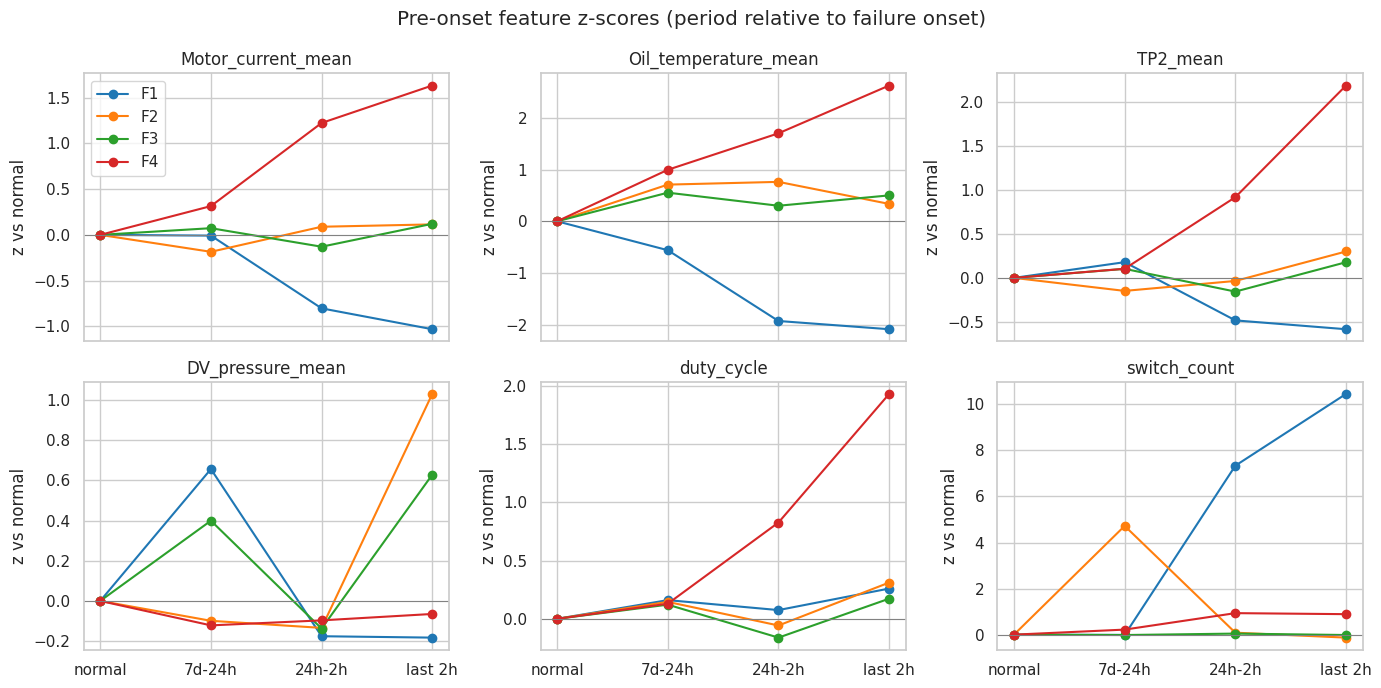

In [28]:
# Plot: one subplot per feature, x = 4 periods, one line per failure.
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
xs = ["normal"] + PERIODS
for ax, f in zip(axes.ravel(), PRECURSOR_FEATS):
    for name, tab in zres.items():
        ax.plot(xs, tab.loc[f, xs].values, marker="o", label=name)
    ax.axhline(0, color="gray", lw=0.7)
    ax.set_title(f)
    ax.set_ylabel("z vs normal")
axes[0, 0].legend()
fig.suptitle("Pre-onset feature z-scores (period relative to failure onset)")
fig.tight_layout()
plt.show()

### 14b. Early-warning models at 2, 6 and 24 h

In [29]:
print("\n", "=" * 78, "\nPART 2: early-warning models\n", "=" * 78, sep="")


def pre_label(index, H):
    """1 if the window lies within H hours BEFORE any failure onset."""
    y = pd.Series(0, index=index)
    for s, _ in FAILS.values():
        y[(index >= s - H * H_) & (index < s)] = 1
    return y


def prep(part, H):
    """Label and DROP windows inside actual failures. They are dropped because
    the question is pure pre-failure prediction: in-failure windows are
    trivially abnormal (detection), and labelling them 0 would punish the model
    for correctly flagging a failure, while labelling them 1 would mix up
    detection with early warning."""
    keep = ~in_failure(part.index)
    p = part[keep]
    return p[FEATURES], pre_label(p.index, H)


summary = []
for H in HORIZONS:
    print(f"\n--- Horizon H = {H} h ---")
    Xtr, ytr = prep(train, H)
    Xva, yva = prep(val, H)
    Xte, yte = prep(test, H)
    print(f"positives: train={ytr.sum()} val={yva.sum()} test={yte.sum()}")
    if min(ytr.sum(), yva.sum(), yte.sum()) == 0:
        print("A split has no positive windows for this horizon; skipping.")
        summary.append((H, np.nan, "skipped", "skipped"))
        continue
    # Scaler on train only, C chosen on VALIDATION only (by AUROC: threshold-
    # free, so it is not distorted by the arbitrary 0.5 cut-off or by
    # degenerate all-zero predictions). The test set never influences choices.
    sc = StandardScaler().fit(Xtr)
    best_C, best_auc = None, -1
    for C in C_GRID:
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=1000).fit(sc.transform(Xtr), ytr)
        auc = roc_auc_score(yva, m.predict_proba(sc.transform(Xva))[:, 1])
        print(f"  C={C:<7} val AUROC={auc:.4f}")
        if auc > best_auc:
            best_C, best_auc = C, auc
    print(f"C selected on validation = {best_C}")
    # Refit scaler+model on train+validation (all data before test), test once.
    Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
    sc2 = StandardScaler().fit(Xtv)
    final = LogisticRegression(C=best_C, class_weight="balanced", max_iter=1000).fit(sc2.transform(Xtv), ytv)
    prob = pd.Series(final.predict_proba(sc2.transform(Xte))[:, 1], index=Xte.index)
    pred = (prob >= 0.5).astype(int)
    auc = roc_auc_score(yte, prob)
    print(f"TEST pre-failure class: AUROC={auc:.4f} "
          f"P={precision_score(yte, pred, zero_division=0):.4f} "
          f"R={recall_score(yte, pred, zero_division=0):.4f} "
          f"F1={f1_score(yte, pred, zero_division=0):.4f}")
    warned = {}
    for name in ("F3", "F4"):
        s, _ = FAILS[name]
        w = pred[(pred.index >= s - H * H_) & (pred.index < s)]
        hit = w[w == 1]
        if len(hit):
            warned[name] = f"yes ({(s - hit.index.min()) / H_:.2f} h ahead)"
        else:
            warned[name] = "no"
        print(f"  {name}: alarm in {H}h before onset? {warned[name]}"
              f"  (max prob in window = {prob[(prob.index >= s - H * H_) & (prob.index < s)].max():.3f})")
    summary.append((H, auc, warned["F3"], warned["F4"]))


PART 2: early-warning models

--- Horizon H = 2 h ---
positives: train=24 val=24 test=48
  C=0.0001  val AUROC=0.5057
  C=0.001   val AUROC=0.4835
  C=0.01    val AUROC=0.4915
  C=0.1     val AUROC=0.5110
  C=1       val AUROC=0.5369
C selected on validation = 1
TEST pre-failure class: AUROC=0.4648 P=0.0023 R=0.5000 F1=0.0046
  F3: alarm in 2h before onset? yes (1.67 h ahead)  (max prob in window = 0.896)
  F4: alarm in 2h before onset? yes (2.00 h ahead)  (max prob in window = 0.923)

--- Horizon H = 6 h ---
positives: train=72 val=72 test=144
  C=0.0001  val AUROC=0.4939
  C=0.001   val AUROC=0.4999
  C=0.01    val AUROC=0.5133
  C=0.1     val AUROC=0.5207
  C=1       val AUROC=0.5339
C selected on validation = 1
TEST pre-failure class: AUROC=0.5437 P=0.0069 R=0.6667 F1=0.0136
  F3: alarm in 6h before onset? yes (5.83 h ahead)  (max prob in window = 0.907)
  F4: alarm in 6h before onset? yes (6.00 h ahead)  (max prob in window = 0.994)

--- Horizon H = 24 h ---
positives: train=242 

### 14c. Summary

In [30]:
print("\n", "=" * 78, "\nPART 3: summary\n", "=" * 78, sep="")
print(f"{'Horizon':>8s} {'Test AUROC':>11s}  {'F3 warned?':<22s}{'F4 warned?':<22s}")
for H, auc, a, b in summary:
    print(f"{str(H) + ' h':>8s} {auc:>11.4f}  {a:<22s}{b:<22s}")

aucs = [s[1] for s in summary if not np.isnan(s[1])]
both = [s for s in summary if s[2].startswith("yes") and s[3].startswith("yes")]
print("\nConclusion:")
if not aucs:
    print("  No horizon had positives in all splits, so early warning could not be tested.")
else:
    best = max(aucs)
    if best < 0.6:
        print(f"  Best test AUROC is {best:.3f}, near 0.5: NO predictive signal for early warning.")
    elif both:
        hs = [s[0] for s in both]
        print(f"  Both test failures were warned at horizon(s) {hs} h; best AUROC {best:.3f}. "
              "Still, only 2 test failures (and 1 per train/val) means this is weak evidence.")
    else:
        print(f"  Best test AUROC is {best:.3f}, but no horizon warned BOTH test failures at "
              "threshold 0.5: warning is not reliable.")
print("  Caveat: with one failure in train, one in validation and two in test, any "
      "horizon result rests on very few events and cannot establish reliability.")


PART 3: summary
 Horizon  Test AUROC  F3 warned?            F4 warned?            
     2 h      0.4648  yes (1.67 h ahead)    yes (2.00 h ahead)    
     6 h      0.5437  yes (5.83 h ahead)    yes (6.00 h ahead)    
    24 h      0.5373  yes (24.00 h ahead)   yes (17.08 h ahead)   

Conclusion:
  Best test AUROC is 0.544, near 0.5: NO predictive signal for early warning.
  Caveat: with one failure in train, one in validation and two in test, any horizon result rests on very few events and cannot establish reliability.


## 15. Comparison with Published Work

**Note:** this is a **reported-vs-reported** comparison, not a head-to-head. The published numbers use different labeling, windowing and splits (and in some cases the original authors' own preprocessing), so differences in the table should not be read as one method beating another. "Same setup?" is **No** for every literature row.

In [33]:
lit = pd.DataFrame([
    ("IJACSA 2025 (Akshitha Mary et al.)", "LSTM + Autoencoder", "80/20", 0.98, 0.434, 0.60, "No"),
    ("IJACSA 2025 baseline", "Sparse Autoencoder", "not stated", 0.80, 0.40, 0.533, "No"),
    ("Najjar et al. 2023", "Random Forest", "not stated", np.nan, np.nan, 0.85, "No (F1 approx., binary)"),
    ("Ours (Section 13)", f"Logistic Regression, C=0.0003, alarm policy thr={THR}, k={K}",
     "chronological train/val/test", round(P, 3), round(R, 3), round(F1, 3), "n/a (our result)"),
], columns=["Source", "Model", "Split", "Precision", "Recall", "F1", "Same setup?"])
display(lit)

,Source,Model,Split,Precision,Recall,F1,Same setup?
0,IJACSA 2025 (Akshitha Mary et al.),LSTM + Autoencoder,80/20,0.980,0.434,0.600,No
1,IJACSA 2025 baseline,Sparse Autoencoder,not stated,0.800,0.400,0.533,No
2,Najjar et al. 2023,Random Forest,not stated,NaN,NaN,0.850,"No (F1 approx., binary)"
3,Ours (Section 13),"Logistic Regression, C=0.0003, alarm policy th...",chronological train/val/test,0.979,0.679,0.802,n/a (our result)


## 16. Key Findings and Conclusion

**Final model (leakage-free, Sections 12-13).** Logistic Regression with `class_weight="balanced"`, with C (0.0003) and the alarm policy (threshold 0.95, 2 consecutive windows) both selected on **validation** only. On the test period it reaches **F1 about 0.80** (0.802), **precision about 0.98** (0.979) and recall 0.679, with **zero false-alarm episodes per week**.

- **Failure 3 (52.5 h) detected**, but only about 5 minutes before onset (+0.08 h).
- **Failure 4 (4.5 h) missed.** Its predicted probability peaks at 0.695, below the 0.95 threshold. The model's largest coefficient is on `DV_pressure_mean`, which sits about 34 standard deviations from normal during failure 3 but at normal level during failure 4, so failure 4 lacks the signature the model relies on. It is also short (55 windows).
- **Simple baseline already works:** the untuned Logistic Regression (C=1) scored F1 0.757 on the exploratory split. The exploratory C=0.01 result was tuned on test, so its higher F1 is optimistic. With C picked on validation, a plain chronological split gives F1 0.776.
- **No early-warning signal:** for 2, 6 and 24 h horizons the test AUROC stays near 0.5 (0.465, 0.545, 0.535). The "warned" flags come from alarms that fire constantly (precision 0.2-2.5%), not from real precursors. This data supports detection of a failure in progress, not prediction.
- **Class imbalance** (about 2% failure windows) was the dominant challenge; K-NN and the train-tuned thresholds collapsed to near-zero recall on test.

**Limitations.** Only 4 failure events exist: one in train, one in validation and two in test. Policy selection rests on a single validation failure, and a single missed or caught failure changes event-level results a lot. Literature comparisons are reported-vs-reported only.

**Future work.** Collect more failure events; use leave-one-failure-out evaluation; and move to remaining-useful-life (RUL) prediction on NASA C-MAPSS.
